In [1]:
# Cell 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Cell 2: Load cleaned dataset

df = pd.read_csv("D:\\stock_market_analysis\\Data\\stock_market.csv.csv")

print("Dataset shape:", df.shape)
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["ETF"].value_counts(dropna=False))

print("\nMissing target values:")
print(df["ETF"].isna().sum())

Dataset shape: (8049, 12)


,Nasdaq Traded,Symbol,Security Name,Listing Exchange,Market Category,ETF,Round Lot Size,Test Issue,Financial Status,CQS Symbol,NASDAQ Symbol,NextShares
0,Y,A,"Agilent Technologies, Inc. Common Stock",N,,N,100.0,N,NaN,A,A,N
1,Y,AA,Alcoa Corporation Common Stock,N,,N,100.0,N,NaN,AA,AA,N
2,Y,AAAU,Perth Mint Physical Gold ETF,P,,Y,100.0,N,NaN,AAAU,AAAU,N
3,Y,AACG,ATA Creativity Global - American Depositary Sh...,Q,G,N,100.0,N,N,NaN,AACG,N
4,Y,AADR,AdvisorShares Dorsey Wright ADR ETF,P,,Y,100.0,N,NaN,AADR,AADR,N



Column names:
['Nasdaq Traded', 'Symbol', 'Security Name', 'Listing Exchange', 'Market Category', 'ETF', 'Round Lot Size', 'Test Issue', 'Financial Status', 'CQS Symbol', 'NASDAQ Symbol', 'NextShares']

Target distribution:
ETF
N    5884
Y    2165
Name: count, dtype: int64

Missing target values:
0


In [3]:
# Cell 3: Prepare features and target

# Remove rows where target is missing
df_model = df.dropna(subset=["ETF"]).copy()

# Standardize target labels
df_model["ETF"] = df_model["ETF"].astype(str).str.strip().str.upper()

# Keep only valid target labels
df_model = df_model[df_model["ETF"].isin(["Y", "N"])].copy()

# Remove identifier columns to reduce memorization
identifier_candidates = [
    "Symbol",
    "Security Name",
    "NASDAQ Symbol",
    "CQS Symbol",
    "NextShares"
]

columns_to_drop = [
    col for col in identifier_candidates
    if col in df_model.columns
]

X = df_model.drop(columns=["ETF"] + columns_to_drop)
y = df_model["ETF"].map({"N": 0, "Y": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures used:")
print(X.columns.tolist())
print("\nTarget distribution:")
print(y.value_counts())

Features shape: (8049, 6)
Target shape: (8049,)

Features used:
['Nasdaq Traded', 'Listing Exchange', 'Market Category', 'Round Lot Size', 'Test Issue', 'Financial Status']

Target distribution:
ETF
0    5884
1    2165
Name: count, dtype: int64


In [4]:
# Cell 4: Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training rows: 6439
Testing rows: 1610

Training target distribution:
ETF
0    4707
1    1732
Name: count, dtype: int64

Testing target distribution:
ETF
0    1177
1     433
Name: count, dtype: int64


In [5]:
# Cell 5: Preprocessing pipeline

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Preprocessing pipeline created successfully!")

Numeric features: ['Round Lot Size']
Categorical features: ['Nasdaq Traded', 'Listing Exchange', 'Market Category', 'Test Issue', 'Financial Status']
Preprocessing pipeline created successfully!


In [6]:
# Cell 6: Train and compare models

models = {
    "Dummy Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for model_name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

    trained_models[model_name] = pipeline

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score
1,Logistic Regression,0.9280,0.7898,0.9977,0.8816
2,Random Forest,0.9280,0.7898,0.9977,0.8816
0,Dummy Baseline,0.7311,0.0000,0.0000,0.0000


Classification Report:
              precision    recall  f1-score   support

 Non-ETF (0)       1.00      0.90      0.95      1177
     ETF (1)       0.79      1.00      0.88       433

    accuracy                           0.93      1610
   macro avg       0.89      0.95      0.91      1610
weighted avg       0.94      0.93      0.93      1610



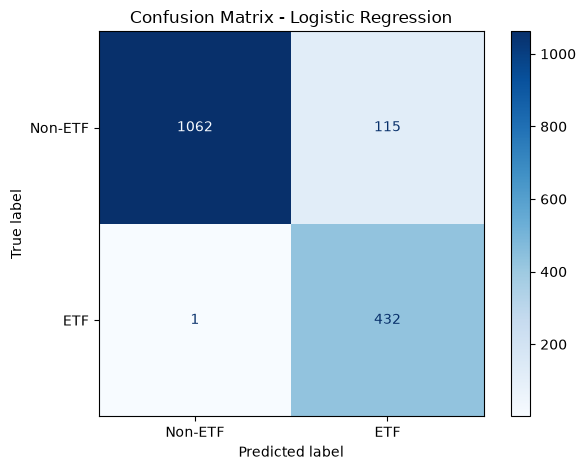

In [7]:
# Cell 7: Evaluate Logistic Regression

model_name = "Logistic Regression"
model = trained_models[model_name]

y_pred = model.predict(X_test)

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Non-ETF (0)", "ETF (1)"],
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Non-ETF", "ETF"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

In [8]:
# Cell 8: ROC-AUC comparison

for model_name, model in trained_models.items():

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, y_prob)
        print(f"{model_name}: ROC-AUC = {auc:.4f}")

Dummy Baseline: ROC-AUC = 0.5000
Logistic Regression: ROC-AUC = 0.9816
Random Forest: ROC-AUC = 0.9806


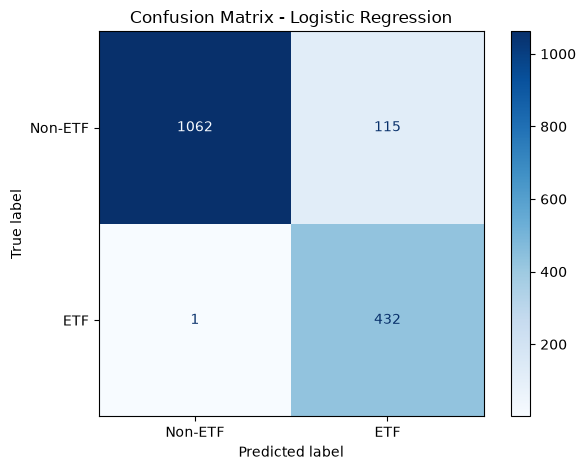

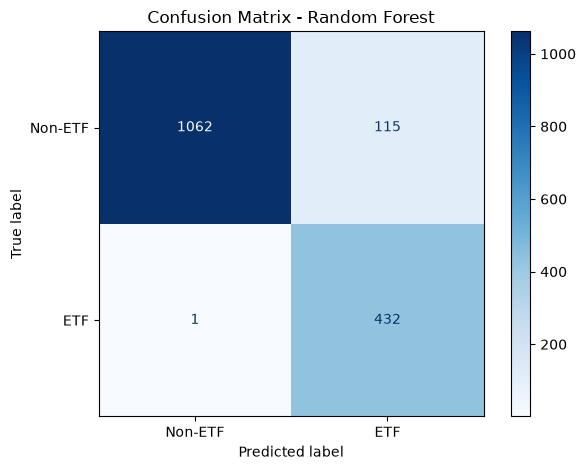

,Model,Correct Predictions,Incorrect Predictions,False Positives,False Negatives
0,Dummy Baseline,1177,433,0,433
1,Logistic Regression,1494,116,115,1
2,Random Forest,1494,116,115,1


In [9]:
# Cell 9: Detailed model evaluation

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

detailed_results = []

for model_name, model in trained_models.items():
    y_pred = model.predict(X_test)

    detailed_results.append({
        "Model": model_name,
        "Correct Predictions": (y_pred == y_test).sum(),
        "Incorrect Predictions": (y_pred != y_test).sum(),
        "False Positives": ((y_pred == 1) & (y_test == 0)).sum(),
        "False Negatives": ((y_pred == 0) & (y_test == 1)).sum()
    })

    if model_name != "Dummy Baseline":
        ConfusionMatrixDisplay.from_predictions(
            y_test,
            y_pred,
            display_labels=["Non-ETF", "ETF"],
            cmap="Blues"
        )
        plt.title(f"Confusion Matrix - {model_name}")
        plt.tight_layout()
        plt.show()

display(pd.DataFrame(detailed_results))

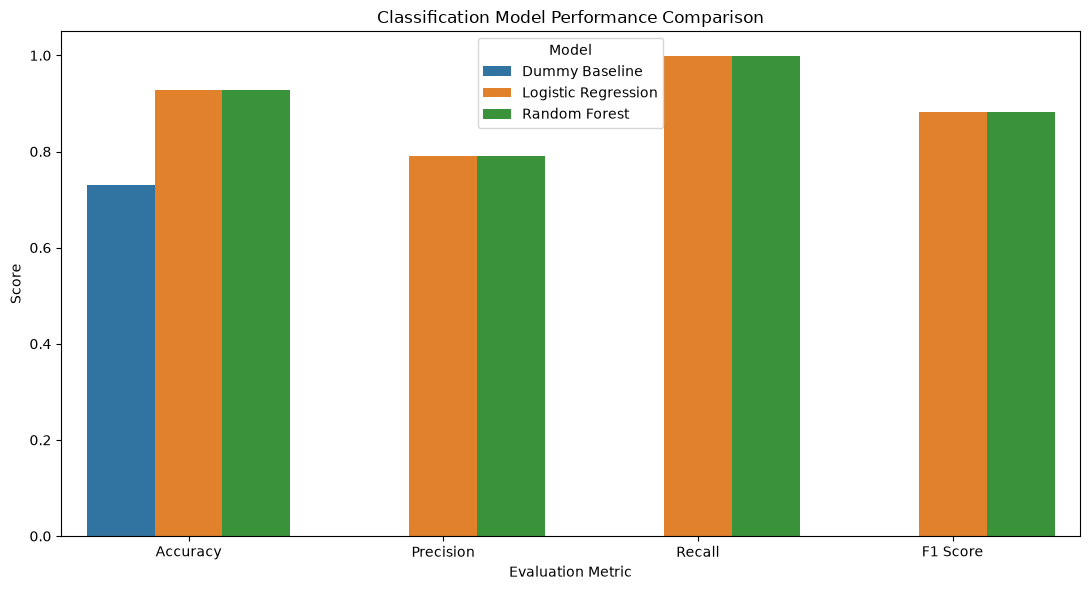

In [10]:
# Cell 10: Compare model performance visually

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.ylim(0, 1.05)
plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.legend(title="Model")
plt.tight_layout()
plt.show()


In [11]:
# Cell 11: Save the trained model

from pathlib import Path
import joblib

project_root = Path.cwd().parent
model_dir = project_root / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "etf_classification_model.joblib"

joblib.dump(
    trained_models["Logistic Regression"],
    model_path
)

print("Model saved successfully!")
print("Saved location:", model_path)

Model saved successfully!
Saved location: d:\stock_market_analysis\models\etf_classification_model.joblib
